# Paprastosios pušies projektas
## 4 dalis. Rekomendacinis pušų sodinimo žemėlapis Lietuvai (5 lygiai)

Šiame sąsiuvinyje 3 dalyje sukurtą RandomForest modelį pritaikome **visai Lietuvai**: sudarome taškų tinklelį (pagal nutylėjimą 1 km), kiekviename taške nuskaitome dirvožemio savybes iš SoilGrids, apskaičiuojame **pušies tinkamumo indeksą** ir nuspalviname šalį **5 lygiais**: nuo „mažiausiai tinkama“ iki „labiausiai tinkama“.

**Prieš pradedant:** turi būti 2 dalies failas `pusis_su_dirvozemiu.csv` ir veikiantis internetas (kaip ir 2 dalyje). Nuskaitymas trunka kelias minutes. Paleiskite langelius iš eilės (Shift + Enter).

**Kaip skaityti žemėlapį:** spalva rodo, kaip dirvožemis konkrečioje vietoje **panašus į vietas, kur pušis stebima**, palyginti su kitomis Lietuvos vietomis. Tai santykinis indeksas, o ne tikra tikimybė (neigiami pavyzdžiai yra atsitiktiniai taškai, žr. ribotumus).

### 1. Bibliotekos ir nustatymai

In [12]:
import time, json, zipfile, io
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import rasterio
from rasterio.warp import transform
from rasterio.windows import Window
from rasterio.transform import from_origin
from matplotlib.path import Path as Kontura
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

# ---------- NUSTATYMAI (galite keisti) ----------
LAUKELIO_KM = 1.0           # tinklelio langelio dydis kilometrais: 2.0 greičiau, 0.5 detaliau
RIBU_METODAS = "kvintiliai" # "kvintiliai" (5 vienodo dydžio lygiai) arba "fiksuotos" (0,2 / 0,4 / 0,6 / 0,8)
RODYTI_GBIF = False         # True = ant žemėlapio uždeda GBIF pušies stebėjimo taškus
# -------------------------------------------------

print("Bibliotekos įkeltos")

Bibliotekos įkeltos


### 2. Modelio paruošimas
Naudojame **tuos pačius** nustatymus kaip 3 dalyje (geriausi hiperparametrai iš GridSearchCV: `n_estimators=200`, `max_depth=6`, `min_samples_leaf=1`) ir tuos pačius 12 dirvožemio požymių. Skirtumas: žemėlapiui modelį apmokome su **visais** 1154 taškais, nes jis bus taikomas visai šaliai, o ne testavimo aibei.

Papildomai gauname „iš aplanko“ (out-of-fold) tikimybes: kiekvieno mokymo taško tikimybė apskaičiuojama modeliu, kuris to taško stačiakampio mokymo metu **nematė**. Jas naudosime kaip sąžiningą žemėlapio lygių patikrą.

In [13]:
rasti = sorted(Path.home().rglob("pusis_su_dirvozemiu.csv"), key=lambda f: f.stat().st_mtime, reverse=True)
if not rasti:
    raise FileNotFoundError("Nerastas pusis_su_dirvozemiu.csv. Pirmiausia paleiskite 2 dalies sąsiuvinį.")
print("Rastas failas:", rasti[0])

df = pd.read_csv(rasti[0])
pozymiai = [c for c in df.columns if c.startswith(("phh2o_", "sand_", "clay_", "soc_"))]
X, y = df[pozymiai], df["pusis"]
print("Eilučių:", len(df), "| požymių:", len(pozymiai))

# Tie patys 0,5° stačiakampiai kaip 3 dalyje
grupes = (np.floor(df["lat"] * 2).astype(int).astype(str) + "_" +
          np.floor(df["lon"] * 2).astype(int).astype(str))
grupes = pd.factorize(grupes)[0]

def naujas_modelis():
    return RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=1,
                                  random_state=42, n_jobs=-1)

rf = naujas_modelis().fit(X, y)
oof = cross_val_predict(naujas_modelis(), X, y, groups=grupes,
                        cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
print("Modelis apmokytas.")

Rastas failas: C:\Users\elmek\pusis_su_dirvozemiu.csv
Eilučių: 1154 | požymių: 12
Modelis apmokytas.


### 3. Lietuvos riba
Kaip 2 dalyje: bandome parsisiųsti ribą iš GADM. Jei nepavyksta, naudojamas stačiakampis (tada žemėlapyje bus ir kaimyninių šalių teritorijos, o tai reikės paminėti ataskaitoje).

In [14]:
GADM_URL = "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_LTU_0.json.zip"

kontura_xy = []   # išoriniai Lietuvos kontūrai (lon, lat), braižymui
try:
    atsakymas = requests.get(GADM_URL, timeout=60)
    atsakymas.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(atsakymas.content)) as z:
        vardas = [n for n in z.namelist() if n.endswith(".json")][0]
        geojson = json.loads(z.read(vardas))
    geom = geojson["features"][0]["geometry"]
    poligonai = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
    for p in poligonai:
        kontura_xy.append(np.array(p[0]))
    print("Lietuvos riba parsisiųsta. Dalių:", len(kontura_xy))
except Exception as klaida:
    print("Ribos parsisiųsti nepavyko:", klaida)
    print("Naudosime stačiakampį aplink Lietuvą.")

kontura_obj = [Kontura(k) for k in kontura_xy]

def lietuvoje(lon, lat):
    taskai = np.column_stack([lon, lat])
    if not kontura_obj:
        return (lat > 53.9) & (lat < 56.45) & (lon > 20.9) & (lon < 26.85)
    vidus = np.zeros(len(taskai), dtype=bool)
    for k in kontura_obj:
        vidus |= k.contains_points(taskai)
    return vidus

Lietuvos riba parsisiųsta. Dalių: 4


### 4. Taškų tinklelis
Per Lietuvą nutiesiame taisyklingą tinklelį (langelio centrai) ir paliekame tik tuos taškus, kurie yra šalies viduje.

In [15]:
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = 53.89, 56.46, 20.90, 26.85
dlat = LAUKELIO_KM / 111.32
dlon = LAUKELIO_KM / (111.32 * np.cos(np.radians(55.2)))

lat_vals = np.arange(LAT_MAX - dlat / 2, LAT_MIN, -dlat)   # iš šiaurės į pietus
lon_vals = np.arange(LON_MIN + dlon / 2, LON_MAX, dlon)
LON, LAT = np.meshgrid(lon_vals, lat_vals)
lon_f, lat_f = LON.ravel(), LAT.ravel()

vidus = lietuvoje(lon_f, lat_f)
lon_t, lat_t = lon_f[vidus], lat_f[vidus]
plotas_km2 = (dlat * 111.32) * (dlon * 111.32 * np.cos(np.radians(lat_t)))

print(f"Tinklelis: {len(lat_vals)} x {len(lon_vals)} langelių")
print(f"Taškų Lietuvos viduje: {len(lon_t)} (apie {plotas_km2.sum():,.0f} km²)")

Tinklelis: 286 x 378 langelių
Taškų Lietuvos viduje: 65087 (apie 64,863 km²)


### 5. Dirvožemio savybių nuskaitymas visam tinkleliui
Kaip 2 dalyje, naudojame ISRIC SoilGrids (phh2o, sand, clay, soc; gyliai 0–5, 5–15, 15–30 cm; vidurkio žemėlapiai). Skirtumas: kadangi taškų daug, kiekvieną žemėlapį nuskaitome **vienu stačiakampiu langu** per Lietuvą, o ne po vieną tašką.

**Pirmiausia išbandome vieną žemėlapį ir penkis taškus.**

In [16]:
BAZE = "https://files.isric.org/soilgrids/latest/data"

def url(savybe, gylis):
    return f"/vsicurl/{BAZE}/{savybe}/{savybe}_{gylis}_mean.vrt"

def nuskaityti_tinkleli(adresas, lon, lat):
    """Nuskaito žemėlapio reikšmes daugelyje taškų (lon, lat). Trūkstama reikšmė = NaN."""
    with rasterio.open(adresas) as src:
        x, y = transform("EPSG:4326", src.crs, list(lon), list(lat))
        x, y = np.asarray(x, dtype="float64"), np.asarray(y, dtype="float64")
        if not (np.isfinite(x).all() and np.isfinite(y).all()):
            raise ValueError("Dalies taškų nepavyko perskaičiuoti į žemėlapio koordinates.")
        t = src.transform
        stulp = np.floor((x - t.c) / t.a).astype(int)
        eil = np.floor((y - t.f) / t.e).astype(int)
        c0, c1 = max(stulp.min() - 1, 0), min(stulp.max() + 2, src.width)
        r0, r1 = max(eil.min() - 1, 0), min(eil.max() + 2, src.height)
        duomenys = src.read(1, window=Window(c0, r0, c1 - c0, r1 - r0)).astype("float64")
        if src.nodata is not None:
            duomenys[duomenys == src.nodata] = np.nan
    rr, cc = eil - r0, stulp - c0
    ok = (rr >= 0) & (rr < duomenys.shape[0]) & (cc >= 0) & (cc < duomenys.shape[1])
    rezultatas = np.full(len(x), np.nan)
    rezultatas[ok] = duomenys[rr[ok], cc[ok]]
    return rezultatas

# Bandymas: pH 0-5 cm, pirmi 5 taškai (turėtų būti skaičiai apie 40-70)
print(nuskaityti_tinkleli(url("phh2o", "0-5cm"), lon_t[:5], lat_t[:5]))

[56. 55. 55. 67. 68.]


- Jei gavote penkis skaičius, einame toliau.
- Jei gavote klaidą ar laukimas užtruko labai ilgai, nukopijuokite klaidos tekstą. Galite padidinti `LAUKELIO_KM` (pvz., 2.0) ir paleisti iš naujo nuo 4 žingsnio.

In [17]:
pradzia = time.time()
reiksmes = {}
for stulpelis in pozymiai:                      # pvz. "phh2o_0-5cm"
    savybe, gylis = stulpelis.split("_", 1)
    reiksmes[stulpelis] = nuskaityti_tinkleli(url(savybe, gylis), lon_t, lat_t) / 10
    print(f"{stulpelis}: baigta (praėjo {time.time() - pradzia:.0f} s)")

Xg = pd.DataFrame(reiksmes)[pozymiai]           # tokia pati stulpelių tvarka kaip mokant modelį
galioja = Xg.notna().all(axis=1).values
print(f"Taškų su visomis dirvožemio reikšmėmis: {galioja.sum()} iš {len(galioja)} "
      f"({100 * galioja.mean():.1f} %). Likę (užstatytos vietos, vandens telkiniai) žemėlapyje bus pilki.")

phh2o_0-5cm: baigta (praėjo 6 s)
phh2o_5-15cm: baigta (praėjo 16 s)
phh2o_15-30cm: baigta (praėjo 27 s)
sand_0-5cm: baigta (praėjo 43 s)
sand_5-15cm: baigta (praėjo 54 s)
sand_15-30cm: baigta (praėjo 73 s)
clay_0-5cm: baigta (praėjo 106 s)
clay_5-15cm: baigta (praėjo 144 s)
clay_15-30cm: baigta (praėjo 169 s)
soc_0-5cm: baigta (praėjo 189 s)
soc_5-15cm: baigta (praėjo 218 s)
soc_15-30cm: baigta (praėjo 258 s)
Taškų su visomis dirvožemio reikšmėmis: 62887 iš 65087 (96.6 %). Likę (užstatytos vietos, vandens telkiniai) žemėlapyje bus pilki.


### 6. Pušies tinkamumo indeksas
Kiekviename taške modelis pateikia klasės „pušis“ tikimybę (0–1). Kadangi neigiami pavyzdžiai yra atsitiktiniai taškai, tai **santykinis tinkamumo indeksas**, o ne tikra tikimybė, kad pušis augs.

In [18]:
p = np.full(len(lon_t), np.nan)
p[galioja] = rf.predict_proba(Xg[galioja])[:, 1]
print("Indekso santrauka:")
print(pd.Series(p[galioja]).describe().round(3))

Indekso santrauka:
count    62887.000
mean         0.350
std          0.234
min          0.005
25%          0.126
50%          0.339
75%          0.547
max          0.859
dtype: float64


### 7. Skirstymas į 5 lygius
- **`kvintiliai`** (numatyta): kiekvienas lygis apima apie 20 % Lietuvos teritorijos. Tai paprasčiausias būdas gauti 5 aiškius lygius, nes modelis silpnas (ROC AUC apie 0,71) ir jo tikimybės telkiasi viduryje.
- **`fiksuotos`**: ribos 0,2 / 0,4 / 0,6 / 0,8; kai kurie lygiai gali likti labai maži ar tušti.

In [19]:
PAVADINIMAI = ["1 – Mažiausiai tinkama", "2 – Menkai tinkama", "3 – Vidutiniškai tinkama",
               "4 – Gerai tinkama", "5 – Labiausiai tinkama"]
SPALVOS = ["#ffffcc", "#c2e699", "#78c679", "#31a354", "#006837"]   # šviesi geltona → tamsiai žalia

if RIBU_METODAS == "kvintiliai":
    ribos = np.quantile(p[galioja], [0.2, 0.4, 0.6, 0.8])
else:
    ribos = np.array([0.2, 0.4, 0.6, 0.8])
print("Lygių ribos (indeksas):", np.round(ribos, 3))

klase = np.full(len(p), np.nan)
klase[galioja] = np.digitize(p[galioja], ribos) + 1

eilutes = []
kraštai = np.concatenate([[p[galioja].min()], ribos, [p[galioja].max()]])
bendras_plotas = plotas_km2[galioja].sum()
for k in range(1, 6):
    m = klase == k
    eilutes.append({"Lygis": PAVADINIMAI[k - 1],
                    "Indekso intervalas": f"{kraštai[k - 1]:.2f} – {kraštai[k]:.2f}",
                    "Plotas, km²": round(plotas_km2[m].sum()),
                    "Dalis, %": round(100 * plotas_km2[m].sum() / bendras_plotas, 1)})
lentele_lygiai = pd.DataFrame(eilutes)
lentele_lygiai

Lygių ribos (indeksas): [0.101 0.242 0.426 0.59 ]


,Lygis,Indekso intervalas,"Plotas, km²","Dalis, %"
0,1 – Mažiausiai tinkama,0.01 – 0.10,12434,19.8
1,2 – Menkai tinkama,0.10 – 0.24,12498,19.9
2,3 – Vidutiniškai tinkama,0.24 – 0.43,12518,20.0
3,4 – Gerai tinkama,0.43 – 0.59,12572,20.1
4,5 – Labiausiai tinkama,0.59 – 0.86,12643,20.2


**Patikra su mokymo taškais (out-of-fold):** kiekvieną mokymo tašką (pušis / atsitiktinis taškas) priskiriame tam pačiam lygiui pagal jo „iš aplanko“ tikimybę. Jei žemėlapis prasmingas, **pušies stebėjimų dalis turi didėti nuo 1 iki 5 lygio**.

In [20]:
klase_oof = np.digitize(oof, ribos) + 1
patikra = (pd.DataFrame({"lygis": klase_oof, "pusis": y.values})
           .groupby("lygis")["pusis"].agg(["count", "mean"]).rename(
               columns={"count": "Taškų", "mean": "Pušies stebėjimų dalis"}).round(3))
patikra.index = [PAVADINIMAI[i - 1] for i in patikra.index]
patikra

,Taškų,Pušies stebėjimų dalis
1 – Mažiausiai tinkama,93,0.108
2 – Menkai tinkama,180,0.167
3 – Vidutiniškai tinkama,244,0.418
4 – Gerai tinkama,283,0.611
5 – Labiausiai tinkama,354,0.630


### 8. Žemėlapis
Pilka spalva – vietos be dirvožemio duomenų. Ploni juodi taškai (jei `RODYTI_GBIF = True`) – GBIF pušies stebėjimai.

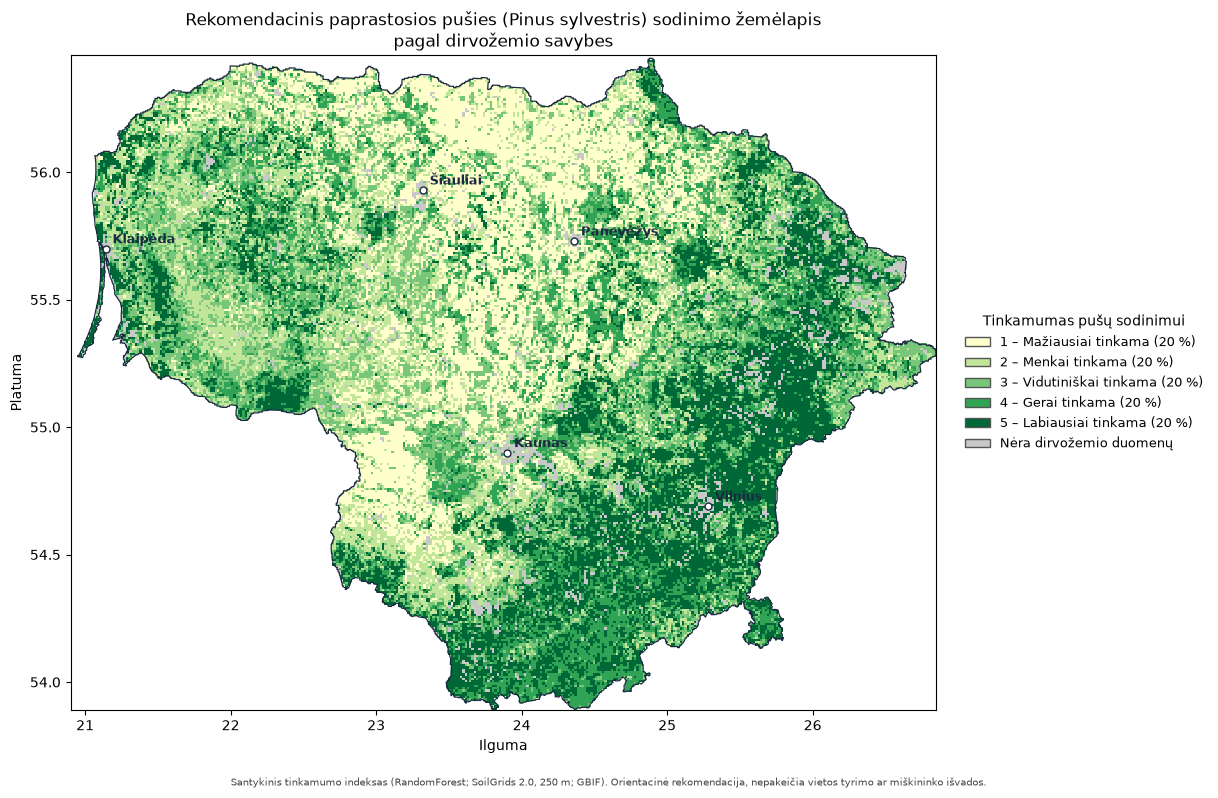

In [21]:
pilnas = np.full(lon_f.shape, np.nan)
pilnas[vidus] = klase
tinklas = np.ma.masked_invalid(pilnas.reshape(LON.shape))

nera = np.full(lon_f.shape, np.nan)
nera[np.where(vidus)[0][~galioja]] = 1
nera_tinklas = np.ma.masked_invalid(nera.reshape(LON.shape))

extent = [lon_vals[0] - dlon / 2, lon_vals[-1] + dlon / 2, lat_vals[-1] - dlat / 2, lat_vals[0] + dlat / 2]
cmap = ListedColormap(SPALVOS)
norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5, 5.5], cmap.N)

fig, ax = plt.subplots(figsize=(11.5, 8))
ax.imshow(nera_tinklas, extent=extent, origin="upper", cmap=ListedColormap(["#c8c8c8"]), interpolation="nearest")
ax.imshow(tinklas, extent=extent, origin="upper", cmap=cmap, norm=norm, interpolation="nearest")
for k in kontura_xy:
    ax.plot(k[:, 0], k[:, 1], color="#1B2A41", lw=0.9)

if RODYTI_GBIF:
    ps = df[df["pusis"] == 1]
    ax.scatter(ps["lon"], ps["lat"], s=4, color="black", alpha=0.6)

MIESTAI = {"Vilnius": (25.28, 54.69), "Kaunas": (23.90, 54.90), "Klaipėda": (21.14, 55.70),
           "Šiauliai": (23.32, 55.93), "Panevėžys": (24.36, 55.73)}
for vardas, (lo, la) in MIESTAI.items():
    ax.plot(lo, la, "o", color="white", mec="#1B2A41", ms=5, zorder=5)
    ax.annotate(vardas, (lo, la), xytext=(5, 4), textcoords="offset points", fontsize=9,
                color="#1B2A41", fontweight="bold", zorder=6)

dalys = lentele_lygiai["Dalis, %"].tolist()
ax.legend(handles=[Patch(fc=SPALVOS[i], ec="#555555", label=f"{PAVADINIMAI[i]} ({dalys[i]:.0f} %)") for i in range(5)]
          + [Patch(fc="#c8c8c8", ec="#555555", label="Nėra dirvožemio duomenų")],
          loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9, title="Tinkamumas pušų sodinimui", title_fontsize=10, frameon=False)
ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
ax.set_aspect(1 / np.cos(np.radians(55.2)))
ax.set_xlabel("Ilguma"); ax.set_ylabel("Platuma")
ax.set_title("Rekomendacinis paprastosios pušies (Pinus sylvestris) sodinimo žemėlapis\npagal dirvožemio savybes", fontsize=12)
fig.text(0.5, 0.01, "Santykinis tinkamumo indeksas (RandomForest; SoilGrids 2.0, 250 m; GBIF). Orientacinė rekomendacija, "
         "nepakeičia vietos tyrimo ar miškininko išvados.", ha="center", fontsize=7.5, color="#444444")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("pusies_sodinimo_zemelapis.png", dpi=200)
plt.show()

### 9. Rezultatų išsaugojimas

In [22]:
# 1) lentelė su kiekvieno taško indeksu ir lygiu (galima atidaryti QGIS ar Excel)
taskai_df = pd.DataFrame({"lon": lon_t, "lat": lat_t, "indeksas": p, "lygis": klase})
taskai_df.to_csv("pusies_sodinimo_zemelapis_taskai.csv", index=False)

# 2) GeoTIFF su lygiais (1–5; 0 = nėra duomenų), EPSG:4326, atidaromas QGIS
raster = np.nan_to_num(pilnas.reshape(LON.shape), nan=0).astype("uint8")
with rasterio.open("pusies_sodinimo_zemelapis.tif", "w", driver="GTiff",
                   height=raster.shape[0], width=raster.shape[1], count=1, dtype="uint8",
                   crs="EPSG:4326", transform=from_origin(extent[0], extent[3], dlon, dlat), nodata=0) as dst:
    dst.write(raster, 1)

print("Išsaugota: pusies_sodinimo_zemelapis.png, pusies_sodinimo_zemelapis_taskai.csv, pusies_sodinimo_zemelapis.tif")

Išsaugota: pusies_sodinimo_zemelapis.png, pusies_sodinimo_zemelapis_taskai.csv, pusies_sodinimo_zemelapis.tif


## Ką užrašyti ataskaitai (naujas poskyris „Rekomendacinis žemėlapis“)
- **Metodas:** 3 dalies RandomForest (200 medžių, `max_depth=6`) apmokytas su visais 1154 taškais; taikytas 1 km tinkleliui Lietuvoje; požymiai – SoilGrids (12 požymių).
- **Lygiai:** 5 kvintilių lygiai (kiekvienas apie 20 % teritorijos) arba fiksuotos ribos; įrašykite ribas ir plotų lentelę iš 7 žingsnio.
- **Patikra:** lentelė su pušies stebėjimų dalimi pagal lygius (7 žingsnis). Jei dalis auga nuo 1 iki 5 lygio, žemėlapis atitinka duomenis; įvertinkite, kiek stipriai.
- **Interpretacija:** spalva rodo, kaip dirvožemis panašus į vietas, kur pušis stebima; tai **ne** prognozė, kad pušis augs ar neaugs.
- **Ribotumai:** pseudo-neigiami pavyzdžiai, GBIF šališkumas (miestai, keliai), sodintos pušys, SoilGrids modeliuoti duomenys, nėra klimato ir drėgmės požymių, silpnas modelis (F1 apie 0,60), todėl ribos tarp lygių yra neryškios. Rekomenduokite naudoti žemėlapį tik kaip pirmą filtrą.